## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputNBAntiBurnout'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

df = df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')

Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,19.0,NaN,58,8.0,9.0,9.6,56.0,35.0,54.0,37,...,Moderate,Never,Yes,No,No,No,No,No,Poor,Needs Attention
1,48.0,NaN,53,1.0,8.0,4.7,36.0,NaN,60.0,60,...,Moderate,Never,No,Yes,No,No,Yes,No,Excellent,Needs Attention
2,42.0,NaN,59,3.0,2.0,4.9,44.0,62.0,53.0,49,...,Moderate,Daily,No,Yes,No,No,No,No,Average,Needs Attention
3,22.0,NaN,49,9.0,8.0,6.3,72.0,65.0,29.0,35,...,High,Never,No,Yes,Yes,Yes,No,Yes,Average,Needs Attention
4,62.0,NaN,39,3.0,9.0,4.3,45.0,52.0,69.0,56,...,Moderate,Weekly,No,Yes,No,No,Yes,No,Poor,Needs Attention


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,1,0,1,3,1,0,1,0,0,1.0,3,1
1,2,3,1,3,0,1,1,0,1,1.0,0,1
2,0,3,1,0,0,1,1,0,0,1.0,2,1
3,2,2,2,3,0,1,0,1,0,0.0,2,1
4,2,3,1,1,0,1,1,0,1,1.0,3,1


### 2.3 Penanganan Missing Values

In [6]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

X = X.fillna(
    X.mean()
)

print(
    '\nJumlah missing value setelah preprocessing:'
)

print(
    X.isnull().sum()
)

Missing value sebelum preprocessing:
Age                                28
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                   37
Work_Life_Balance                  60
Sleep_Hours                        85
Anxiety_Score                      80
Depression_Score                   73
Mood_Score                         91
Emotional_Stability                 0
Physical_Activity_Hours           100
Meditation_Minutes                122
Screen_Time_Hours                  84
Social_Media_Hours                 62
Gaming_Hours                       69
Coffee_Cups_Per_Day                 0
Life_Satisfaction                  75
Productivity_Score                 80
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Penanganan Outlier

### 2.5 Standardisasi

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X
)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_scaled

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.000000,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,0.982159,-0.403808,-0.973550,1.014305,1.351177,0.353005
1,0.452453,0.000000,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005
2,0.022608,0.000000,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,0.982159,-0.403808,-0.973550,1.014305,0.453862,0.353005
3,-1.410210,0.000000,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,-1.018165,2.476422,-0.973550,-0.994449,0.453862,0.353005
4,1.455425,0.000000,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,1.351177,0.353005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.667376,0.195668,1.705936,-1.605736,-0.180672,-0.618989,1.518814,2.001572,-1.575281,-1.343280,...,1.811640,-0.472624,1.031702,-0.989654,0.982159,2.476422,-0.973550,1.014305,-0.443453,1.610144
4996,0.452453,-0.044840,-0.617185,-0.907749,0.166747,-0.618989,0.781572,0.345256,-0.282377,-0.959519,...,0.390969,-1.360347,1.031702,1.010455,-1.018165,-0.403808,-0.973550,-0.994449,1.351177,0.353005
4997,-0.837083,-1.379573,1.159320,0.488225,0.861585,-1.497599,2.178451,1.616382,-2.202144,-2.187555,...,1.811640,-0.472624,-0.969272,1.010455,0.982159,2.476422,-0.973550,1.014305,0.453862,1.610144
4998,0.452453,0.110154,1.569282,0.139232,-0.875510,-1.321877,0.083133,0.191180,-0.047304,0.076637,...,0.390969,-1.360347,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005


### 2.6 Data Bersih

In [8]:
print('Dimensi data fitur (X):', X.shape)
print('Dimensi data fitur terstandarisasi (X_scaled):', X_scaled.shape)
print('Dimensi data latih (X_train):', X_train.shape)
print('Dimensi data uji (X_test):', X_test.shape)
print('Jumlah missing value:', X_scaled.isnull().sum().sum())
print('\nDistribusi kelas target (y):')
print(y.value_counts())

X_scaled.head()

Dimensi data fitur (X): (5000, 31)
Dimensi data fitur terstandarisasi (X_scaled): (5000, 31)
Dimensi data latih (X_train): (4000, 31)
Dimensi data uji (X_test): (1000, 31)
Jumlah missing value: 0

Distribusi kelas target (y):
Burnout_Risk
0    2481
1    1512
2    1007
Name: count, dtype: int64


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Mental_Health_Status
0,-1.625133,0.0,0.886011,0.837219,1.209004,1.548248,0.587561,-0.232529,-0.204019,-0.844390,...,0.390969,1.302823,1.031702,-0.989654,0.982159,-0.403808,-0.973550,1.014305,1.351177,0.353005
1,0.452453,0.0,0.544376,-1.605736,0.861585,-1.321877,-0.188482,0.000000,0.031054,0.038261,...,0.390969,1.302823,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,-1.340769,0.353005
2,0.022608,0.0,0.954338,-0.907749,-1.222929,-1.204729,0.121935,0.807484,-0.243198,-0.383877,...,0.390969,-1.360347,-0.969272,1.010455,0.982159,-0.403808,-0.973550,1.014305,0.453862,0.353005
3,-1.410210,0.0,0.271067,1.186213,0.861585,-0.384693,1.208396,0.923041,-1.183492,-0.921143,...,1.811640,1.302823,-0.969272,1.010455,-1.018165,2.476422,-0.973550,-0.994449,0.453862,0.353005
4,1.455425,0.0,-0.412204,-0.907749,1.209004,-1.556173,0.160737,0.422294,0.383664,-0.115244,...,0.390969,-0.472624,-0.969272,1.010455,0.982159,-0.403808,1.027169,1.014305,1.351177,0.353005


## 3. Modeling

### 3.1 Inisialisasi Model Naive Bayes Gaussian

In [9]:
# Dimodifikasi dari BernoulliNB (jurnal) ke GaussianNB karena fitur X_scaled berupa data kontinu terstandarisasi
model = GaussianNB(
    var_smoothing=1e-9
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [10]:
tracemalloc.start()
start_time = time.process_time()

model.fit(
    X_train,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 0.0000 detik
Penggunaan Memori Peak: 1.1779 MB


### 3.3 Prediksi Data Uji

In [11]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
761,1,1
4863,0,0
3651,0,0
361,1,1
3197,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [12]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     1.0000    1.0000    1.0000       496
Moderate (1)     1.0000    0.9637    0.9815       303
    High (2)     0.9481    1.0000    0.9734       201

    accuracy                         0.9890      1000
   macro avg     0.9827    0.9879    0.9850      1000
weighted avg     0.9896    0.9890    0.9890      1000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[496   0   0]
 [  0 292  11]
 [  0   0 201]]


### 4.3 Metrik Evaluasi Data Uji

In [14]:
acc = accuracy_score(
    y_test,
    y_pred
)

prec_macro = precision_score(
    y_test,
    y_pred,
    average='macro'
)

rec_macro = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average='macro'
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.9890
Precision (Macro)  : 0.9827
Recall (Macro)     : 0.9879
F1-Score (Macro)   : 0.9850
F1-Score (Weighted): 0.9890


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

cv_results = cross_validate(
    model,
    X_scaled,
    y,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.985000,0.976852,0.983498,0.979549,0.985079
1,Fold 2,0.985000,0.976852,0.983498,0.979549,0.985079
2,Fold 3,0.984000,0.975535,0.982340,0.978231,0.984087
3,Fold 4,0.986000,0.978395,0.984547,0.980926,0.986068
4,Fold 5,0.990000,0.984202,0.988962,0.986298,0.990037
Mean,NaN,0.986000,0.978367,0.984569,0.980911,0.986070
Std,NaN,0.002098,0.003055,0.002305,0.002825,0.002080


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [16]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Naive Bayes (GaussianNB)',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Naive Bayes (GaussianNB),0.0,1.1779


### 4.6 Ringkasan Evaluasi Model

In [17]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['Naive Bayes (GaussianNB)'],
        'Distribusi': ['Gaussian'],
        'Var_Smoothing': [1e-9],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Distribusi,Var_Smoothing,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Naive Bayes (GaussianNB),Gaussian,1.000000e-09,0.989,0.9827,0.9879,0.985,0.989,0.986,0.9809,0.0,1.1779


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

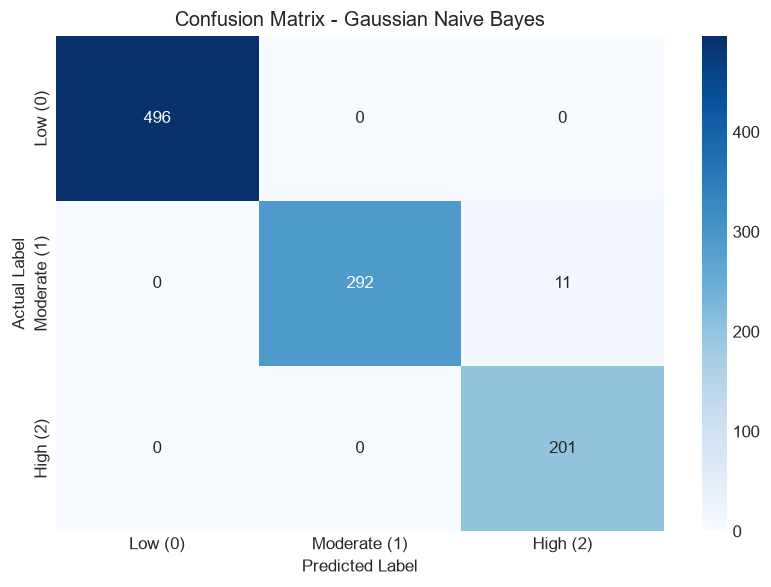

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_nb.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

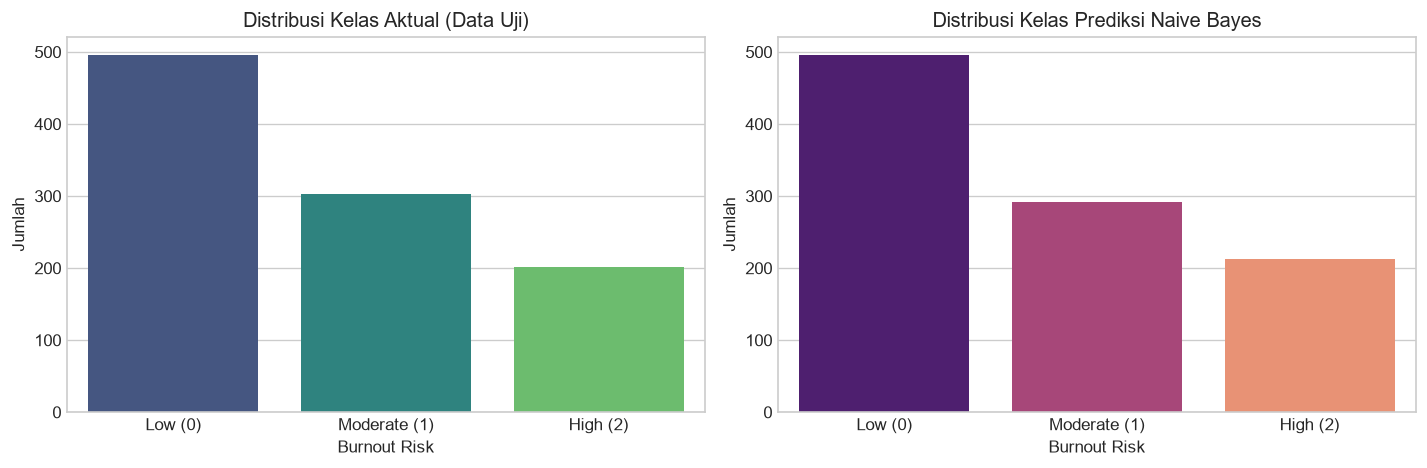

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    x=y_test,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xticklabels(target_names)
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

sns.countplot(
    x=y_pred,
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('Distribusi Kelas Prediksi Naive Bayes')
axes[1].set_xticklabels(target_names)
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_nb.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

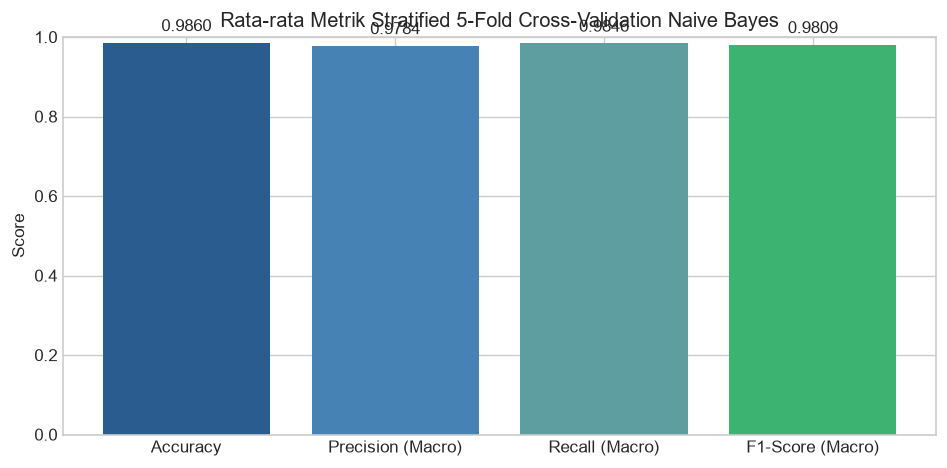

In [20]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    cv_results['test_accuracy'].mean(),
    cv_results['test_precision_macro'].mean(),
    cv_results['test_recall_macro'].mean(),
    cv_results['test_f1_macro'].mean()
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation Naive Bayes')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_nb.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Prior Probabilitas dan Rata-rata Fitur per Kelas (Gaussian Theta)

In [21]:
df_priors = pd.DataFrame(
    {
        'Kelas': target_names,
        'Prior_Probability': [round(p, 4) for p in model.class_prior_]
    }
)

df_theta = pd.DataFrame(
    model.theta_,
    columns=X.columns,
    index=target_names
)

print('Prior Probability per Kelas:')
display(df_priors)
print('\nRata-rata Nilai Fitur Terstandarisasi (Theta) per Kelas (10 Fitur Pertama):')
df_theta.T.head(10)

Prior Probability per Kelas:


,Kelas,Prior_Probability
0,Low (0),0.4962
1,Moderate (1),0.3022
2,High (2),0.2015



Rata-rata Nilai Fitur Terstandarisasi (Theta) per Kelas (10 Fitur Pertama):


,Low (0),Moderate (1),High (2)
Age,0.025140,-0.045824,0.011474
Monthly_Income_USD,0.020477,-0.022537,0.008559
Work_Hours_Per_Week,-0.536535,0.288870,0.891013
Job_Satisfaction,0.001395,-0.012256,0.029428
Work_Life_Balance,0.004943,0.054309,-0.050187
Sleep_Hours,0.185833,-0.117172,-0.295986
Anxiety_Score,-0.764514,0.372772,1.346508
Depression_Score,-0.759940,0.359740,1.348254
Mood_Score,0.757063,-0.363361,-1.332668
Emotional_Stability,0.763773,-0.373275,-1.343280


### 6.2 Perbandingan Kinerja GaussianNB vs BernoulliNB (Jurnal)

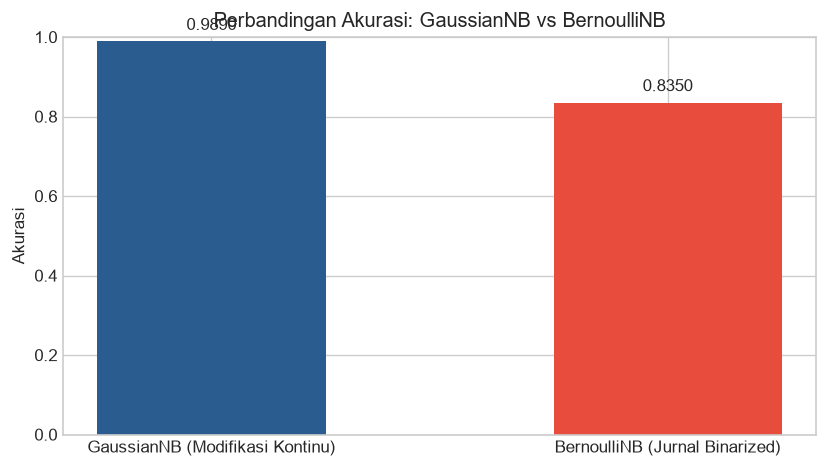

,Varian_NB,Akurasi,F1_Score_Macro
0,GaussianNB (Modifikasi Kontinu),0.989,0.9850
1,BernoulliNB (Jurnal Binarized),0.835,0.7974


In [22]:
model_bernoulli = BernoulliNB(
    alpha=1.0,
    binarize=0.0
)

model_bernoulli.fit(
    X_train,
    y_train
)

y_pred_bern = model_bernoulli.predict(
    X_test
)

acc_bern = accuracy_score(y_test, y_pred_bern)
f1_bern = f1_score(y_test, y_pred_bern, average='macro')

df_nb_comp = pd.DataFrame(
    {
        'Varian_NB': ['GaussianNB (Modifikasi Kontinu)', 'BernoulliNB (Jurnal Binarized)'],
        'Akurasi': [round(acc, 4), round(acc_bern, 4)],
        'F1_Score_Macro': [round(f1_macro, 4), round(f1_bern, 4)]
    }
)

plt.figure(figsize=(7, 4))
bars_comp = plt.bar(
    df_nb_comp['Varian_NB'],
    df_nb_comp['Akurasi'],
    color=['#2b5c8f', '#e74c3c'],
    width=0.5
)
plt.title('Perbandingan Akurasi: GaussianNB vs BernoulliNB')
plt.ylabel('Akurasi')
plt.ylim(0, 1)

for bar in bars_comp:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/comparison_gaussian_vs_bernoulli.png'
)
plt.show()

df_nb_comp

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [23]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_nb_antiburnout.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [24]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_nb_antiburnout.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [25]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_nb_antiburnout.csv'
)

### 7.4 Ekspor Hasil Komparasi Varian Naive Bayes

In [26]:
df_nb_comp.to_csv(
    f'{OUTPUT_DIR}/nb_variants_comparison.csv',
    index=False
)